<a href="https://colab.research.google.com/github/Dhairya-1103/UCS420CognitiveComputing/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install nltk scikit-learn pandas matplotlib seaborn

In [ ]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

STOP_WORDS = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
training_data = [
    # symptoms
    ("What are common signs of heart disease?", "symptoms"),
    ("Why do I feel short of breath when walking?", "symptoms"),
    ("Can heart problems cause tiredness?", "symptoms"),
    ("What does an irregular heartbeat feel like?", "symptoms"),
    ("Is swelling in the ankles related to the heart?", "symptoms"),
    ("Can chest discomfort be a symptom of a heart condition?", "symptoms"),
    ("What are possible symptoms of an abnormal heart rhythm?", "symptoms"),
    ("Why might someone feel dizzy with a heart condition?", "symptoms"),

    # risk factors
    ("What are the risk factors for heart disease?", "risk_factors"),
    ("Does smoking increase the risk of heart disease?", "risk_factors"),
    ("Can high blood pressure affect the heart?", "risk_factors"),
    ("Is diabetes linked to cardiovascular disease?", "risk_factors"),
    ("Does family history matter for heart disease?", "risk_factors"),
    ("How does high cholesterol affect heart health?", "risk_factors"),
    ("Can obesity increase cardiovascular risk?", "risk_factors"),
    ("Does stress contribute to heart disease risk?", "risk_factors"),

    # screening
    ("When should someone get a heart health checkup?", "screening"),
    ("What should I discuss during a cardiovascular screening?", "screening"),
    ("How often should blood pressure be checked?", "screening"),
    ("Who may need cholesterol screening?", "screening"),
    ("What happens during a routine heart checkup?", "screening"),
    ("Can a doctor assess my family history for heart risk?", "screening"),
    ("What health measurements are checked in a heart screening?", "screening"),
    ("Should adults ask their doctor about cardiovascular screening?", "screening"),

    # diet
    ("What foods are good for heart health?", "diet"),
    ("What is a heart healthy diet?", "diet"),
    ("Should I reduce salt to protect my heart?", "diet"),
    ("Are fruits and vegetables helpful for cardiovascular health?", "diet"),
    ("What fats should I limit for heart health?", "diet"),
    ("Is a diet high in fibre good for the heart?", "diet"),
    ("How can I make my meals more heart friendly?", "diet"),
    ("What eating habits support a healthy heart?", "diet"),

    # exercise
    ("What exercise supports heart health?", "exercise"),
    ("How does walking benefit the heart?", "exercise"),
    ("Is regular physical activity good for the heart?", "exercise"),
    ("How can I become more active safely?", "exercise"),
    ("Does cycling improve cardiovascular fitness?", "exercise"),
    ("What are examples of aerobic exercise?", "exercise"),
    ("How often should adults be physically active?", "exercise"),
    ("Can swimming support cardiovascular health?", "exercise"),

    # tests
    ("What is an ECG test used for?", "tests"),
    ("How does an electrocardiogram work?", "tests"),
    ("What is an echocardiogram?", "tests"),
    ("Why might a doctor order a stress test?", "tests"),
    ("What does a cholesterol blood test measure?", "tests"),
    ("What is a cardiac imaging test?", "tests"),
    ("How is heart rhythm monitored?", "tests"),
    ("What happens during an exercise stress test?", "tests"),

    # medication
    ("What medicines are commonly used for heart conditions?", "medication"),
    ("Why might a doctor prescribe blood pressure medicine?", "medication"),
    ("Can I stop taking my prescribed heart medicine?", "medication"),
    ("Should I change the dose of my heart medication?", "medication"),
    ("What should I ask my doctor about a new heart medicine?", "medication"),
    ("Can heart medicines have side effects?", "medication"),
    ("Why is it important to take prescribed medicine as directed?", "medication"),
    ("Who can explain interactions with my heart medication?", "medication"),

    # follow-up
    ("What should I ask at my cardiology follow up?", "follow_up"),
    ("How can I prepare for a heart specialist appointment?", "follow_up"),
    ("What information should I bring to a heart checkup?", "follow_up"),
    ("How do I keep track of questions for my cardiologist?", "follow_up"),
    ("What should I discuss after a heart test?", "follow_up"),
    ("When should I contact my doctor after a heart appointment?", "follow_up"),
    ("How can I understand my doctor's heart care plan?", "follow_up"),
    ("What details should I record before a follow up visit?", "follow_up"),
]

df = pd.DataFrame(training_data, columns=["query", "intent"])
print("Total labelled queries:", len(df))
print("\nExamples per intent:")
display(df["intent"].value_counts().rename("count").to_frame())
display(df.head(10))

Total labelled queries: 64

Examples per intent:


,count
intent,
symptoms,8
risk_factors,8
screening,8
diet,8
exercise,8
tests,8
medication,8
follow_up,8


,query,intent
0,What are common signs of heart disease?,symptoms
1,Why do I feel short of breath when walking?,symptoms
2,Can heart problems cause tiredness?,symptoms
3,What does an irregular heartbeat feel like?,symptoms
4,Is swelling in the ankles related to the heart?,symptoms
5,Can chest discomfort be a symptom of a heart c...,symptoms
6,What are possible symptoms of an abnormal hear...,symptoms
7,Why might someone feel dizzy with a heart cond...,symptoms
8,What are the risk factors for heart disease?,risk_factors
9,Does smoking increase the risk of heart disease?,risk_factors


In [ ]:
taxonomy = {
    "Symptoms": {
        "Common symptoms": "symptoms",
        "Emergency warning signs": "emergency_rule"
    },
    "Risk assessment": {
        "Risk factors": "risk_factors",
        "Preventive screening": "screening"
    },
    "Prevention and wellness": {
        "Heart healthy diet": "diet",
        "Physical activity": "exercise"
    },
    "Care and treatment": {
        "Diagnostic tests": "tests",
        "Medication information": "medication",
        "Follow-up care": "follow_up"
    }
}

for major, subcategories in taxonomy.items():
    print(major)
    for sub, intent in subcategories.items():
        print(f"  - {sub} [{intent}]")

Symptoms
  - Common symptoms [symptoms]
  - Emergency warning signs [emergency_rule]
Risk assessment
  - Risk factors [risk_factors]
  - Preventive screening [screening]
Prevention and wellness
  - Heart healthy diet [diet]
  - Physical activity [exercise]
Care and treatment
  - Diagnostic tests [tests]
  - Medication information [medication]
  - Follow-up care [follow_up]


In [ ]:
domain_concepts = {
    "Heart": "Organ that circulates blood through the body.",
    "Blood pressure": "Pressure of circulating blood against artery walls.",
    "Cholesterol": "A blood lipid measured as part of cardiovascular risk assessment.",
    "Diabetes": "A condition associated with increased cardiovascular risk.",
    "Smoking": "A behaviour that increases cardiovascular risk.",
    "Physical activity": "Movement that supports cardiovascular fitness.",
    "Heart healthy diet": "Eating pattern emphasizing balanced, nutrient-rich foods.",
    "ECG": "Test that records the electrical activity of the heart.",
    "Echocardiogram": "Ultrasound imaging used to examine heart structure and function.",
    "Medication": "Treatment prescribed by a qualified healthcare professional.",
    "Cardiologist": "Doctor specializing in heart and cardiovascular conditions.",
    "Emergency symptoms": "Warning signs that may require urgent medical assessment."
}

relationships = [
    ("High blood pressure", "increases risk to", "Heart"),
    ("Diabetes", "is associated with increased risk of", "Heart disease"),
    ("Smoking", "increases risk of", "Heart disease"),
    ("Cholesterol", "is assessed in", "Cardiovascular screening"),
    ("Physical activity", "supports", "Heart health"),
    ("Heart healthy diet", "supports", "Heart health"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Echocardiogram", "images", "Heart"),
    ("Cardiologist", "evaluates", "Heart conditions"),
    ("Medication", "may be prescribed for", "Heart conditions"),
    ("Emergency symptoms", "require urgent assessment of", "Person"),
    ("Cardiovascular screening", "may include measurement of", "Blood pressure")
]

print("Number of domain concepts:", len(domain_concepts))
for concept, description in domain_concepts.items():
    print(f"- {concept}: {description}")

print("\nDomain relationships:")
for subject, relation, obj in relationships:
    print(f"{subject} --{relation}--> {obj}")

Number of domain concepts: 12
- Heart: Organ that circulates blood through the body.
- Blood pressure: Pressure of circulating blood against artery walls.
- Cholesterol: A blood lipid measured as part of cardiovascular risk assessment.
- Diabetes: A condition associated with increased cardiovascular risk.
- Smoking: A behaviour that increases cardiovascular risk.
- Physical activity: Movement that supports cardiovascular fitness.
- Heart healthy diet: Eating pattern emphasizing balanced, nutrient-rich foods.
- ECG: Test that records the electrical activity of the heart.
- Echocardiogram: Ultrasound imaging used to examine heart structure and function.
- Medication: Treatment prescribed by a qualified healthcare professional.
- Cardiologist: Doctor specializing in heart and cardiovascular conditions.
- Emergency symptoms: Warning signs that may require urgent medical assessment.

Domain relationships:
High blood pressure --increases risk to--> Heart
Diabetes --is associated with increas

In [ ]:
def preprocess_text(text):
    text = text.lower()
    tokens = re.findall(r"[a-z]+", text)
    tokens = [
        LEMMATIZER.lemmatize(token)
        for token in tokens
        if token not in STOP_WORDS and len(token) > 1
    ]
    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess_text)
display(df[["query", "processed_query", "intent"]].head(10))

,query,processed_query,intent
0,What are common signs of heart disease?,common sign heart disease,symptoms
1,Why do I feel short of breath when walking?,feel short breath walking,symptoms
2,Can heart problems cause tiredness?,heart problem cause tiredness,symptoms
3,What does an irregular heartbeat feel like?,irregular heartbeat feel like,symptoms
4,Is swelling in the ankles related to the heart?,swelling ankle related heart,symptoms
5,Can chest discomfort be a symptom of a heart c...,chest discomfort symptom heart condition,symptoms
6,What are possible symptoms of an abnormal hear...,possible symptom abnormal heart rhythm,symptoms
7,Why might someone feel dizzy with a heart cond...,might someone feel dizzy heart condition,symptoms
8,What are the risk factors for heart disease?,risk factor heart disease,risk_factors
9,Does smoking increase the risk of heart disease?,smoking increase risk heart disease,risk_factors


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["query"],
    df["intent"],
    test_size=0.25,
    random_state=42,
    stratify=df["intent"]
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        preprocessor=preprocess_text,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Model training complete.")
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Model training complete.
Training examples: 48
Testing examples: 16


In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.562
Precision: 0.675
Recall   : 0.562
F1-score : 0.555

Classification Report:
              precision    recall  f1-score   support

        diet       1.00      0.50      0.67         2
    exercise       0.00      0.00      0.00         2
   follow_up       1.00      0.50      0.67         2
  medication       1.00      0.50      0.67         2
risk_factors       0.67      1.00      0.80         2
   screening       0.40      1.00      0.57         2
    symptoms       0.33      0.50      0.40         2
       tests       1.00      0.50      0.67         2

    accuracy                           0.56        16
   macro avg       0.68      0.56      0.55        16
weighted avg       0.68      0.56      0.55        16



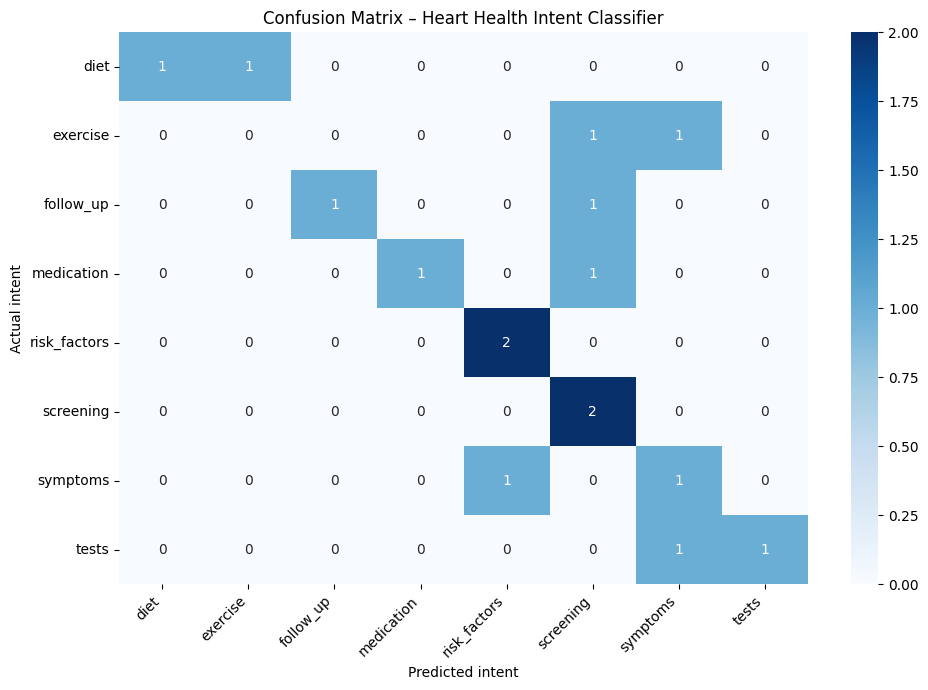

In [ ]:
labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Confusion Matrix – Heart Health Intent Classifier")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
knowledge_base = {
    "symptoms": (
        "Possible symptoms associated with heart conditions can include chest discomfort, "
        "shortness of breath, unusual fatigue, dizziness, palpitations, or swelling. "
        "These symptoms can have many causes and cannot establish a diagnosis. "
        "A healthcare professional can assess persistent or concerning symptoms."
    ),
    "risk_factors": (
        "Factors associated with cardiovascular risk include high blood pressure, "
        "high cholesterol, diabetes, smoking, physical inactivity, and family history. "
        "A clinician can interpret these factors in the context of an individual's health."
    ),
    "screening": (
        "A preventive checkup may include discussion of medical and family history, "
        "blood pressure measurement, and blood tests such as cholesterol or glucose "
        "when appropriate. Ask a healthcare professional which checks are suitable."
    ),
    "diet": (
        "General heart healthy eating patterns emphasize vegetables, fruits, whole grains, "
        "beans, nuts, and suitable sources of protein. Limiting excess salt, highly processed "
        "foods, and trans fats may support cardiovascular health. Individual dietary needs vary."
    ),
    "exercise": (
        "Regular physical activity can support cardiovascular fitness. Walking, cycling, "
        "swimming, and other suitable aerobic activities are examples. Start at a level "
        "appropriate to your abilities and ask a clinician before changing activity if you "
        "have symptoms or a known heart condition."
    ),
    "tests": (
        "An ECG records the heart's electrical activity. An echocardiogram uses ultrasound "
        "to create images of the heart. Other tests may be considered depending on symptoms "
        "and clinical assessment. A healthcare professional should explain the purpose and "
        "meaning of any test."
    ),
    "medication": (
        "Heart-related medicines vary by condition and individual circumstances. Take medicines "
        "only as prescribed. Do not start, stop, or change a dose based on chatbot information; "
        "ask your prescribing clinician or pharmacist about side effects and interactions."
    ),
    "follow_up": (
        "For a heart-related appointment, consider bringing a list of symptoms, current "
        "medicines, relevant medical history, test reports, and questions. Ask the clinician "
        "to explain the care plan, follow-up timing, and which changes should prompt contact."
    )
}

print("Knowledge base entries:", len(knowledge_base))
for key in knowledge_base:
    print("-", key)

Knowledge base entries: 8
- symptoms
- risk_factors
- screening
- diet
- exercise
- tests
- medication
- follow_up


In [ ]:
EMERGENCY_PATTERNS = [
    r"chest pain",
    r"severe chest pressure",
    r"cannot breathe",
    r"can't breathe",
    r"severe shortness of breath",
    r"faint(ed|ing)?",
    r"unconscious",
    r"stroke symptoms",
    r"blue lips"
]

HEART_DOMAIN_TERMS = {
    "heart", "cardiac", "cardiovascular", "chest", "blood pressure",
    "cholesterol", "ecg", "echocardiogram", "cardiologist", "pulse",
    "heartbeat", "palpitation", "heart disease", "heart attack", "ticker"
}

MEDICATION_TERMS = {
    "medicine", "medication", "dose", "dosage", "tablet", "pills",
    "prescription", "drug", "side effect"
}

def is_emergency(query):
    q = query.lower()
    return any(re.search(pattern, q) for pattern in EMERGENCY_PATTERNS)

def is_heart_domain(query):
    q = query.lower()
    return any(term in q for term in HEART_DOMAIN_TERMS)

def is_medication_query(query):
    q = query.lower()
    return any(term in q for term in MEDICATION_TERMS)

def assistant_response(query, threshold=0.30):
    query = query.strip()

    if not query:
        return "Please enter a question about heart health."

    # Rule 1: Emergency escalation always takes priority.
    if is_emergency(query):
        return (
            "EMERGENCY ALERT: Symptoms such as chest pain, severe breathing difficulty, "
            "fainting, or loss of consciousness may be signs of a medical emergency. "
            "Call emergency services now (112 in India, or your local emergency number). "
            "Do not wait for an online response or drive yourself. This assistant cannot "
            "assess or rule out an emergency."
        )

    # Rule 2: Unsupported-domain handling.
    if not is_heart_domain(query):
        return (
            "I can currently answer general heart-health questions only. "
            "Please ask about heart symptoms, risk factors, screening, diet, exercise, "
            "heart tests, medication information, or follow-up care."
        )

    # Rule 3: Low-confidence handling.
    probabilities = model.predict_proba([query])[0]
    best_index = int(np.argmax(probabilities))
    confidence = float(probabilities[best_index])
    predicted_intent = model.classes_[best_index]

    if confidence < threshold:
        return (
            "I'm not sufficiently confident about the intent of your question. "
            "Could you rephrase it or specify whether you are asking about symptoms, "
            "risk factors, screening, diet, exercise, tests, medication, or follow-up care? "
            "For personal medical advice, contact a healthcare professional."
        )

    # Rule 4: Medication safety.
    if predicted_intent == "medication" or is_medication_query(query):
        answer = knowledge_base["medication"]
    else:
        answer = knowledge_base[predicted_intent]

    # Rule 5: Educational disclaimer.
    return (
        f"Detected intent: {predicted_intent} (confidence: {confidence:.2f})\n\n"
        f"{answer}\n\n"
        "Disclaimer: This is general educational information, not a diagnosis or "
        "a substitute for advice from a qualified healthcare professional."
    )

print("Safety rules configured.")

Safety rules configured.


In [ ]:
test_cases = [
    ("Intent query – diet", "What should I eat to keep my heart healthy?"),
    ("Differently worded query", "Does going for a walk help my ticker?"),
    ("Unsupported query", "How do I repair a bicycle tyre?"),
    ("Low-confidence query", "My heart topic is confusing and I have a question about it."),
    ("Emergency query", "I have severe chest pain and cannot breathe.")
]

for title, query in test_cases:
    print("=" * 80)
    print(title)
    print("User:", query)
    print("Assistant:", assistant_response(query))
    print()

Intent query – diet
User: What should I eat to keep my heart healthy?
Assistant: I'm not sufficiently confident about the intent of your question. Could you rephrase it or specify whether you are asking about symptoms, risk factors, screening, diet, exercise, tests, medication, or follow-up care? For personal medical advice, contact a healthcare professional.

Differently worded query
User: Does going for a walk help my ticker?
Assistant: I'm not sufficiently confident about the intent of your question. Could you rephrase it or specify whether you are asking about symptoms, risk factors, screening, diet, exercise, tests, medication, or follow-up care? For personal medical advice, contact a healthcare professional.

Unsupported query
User: How do I repair a bicycle tyre?
Assistant: I can currently answer general heart-health questions only. Please ask about heart symptoms, risk factors, screening, diet, exercise, heart tests, medication information, or follow-up care.

Low-confidence qu

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

query_box = widgets.Textarea(
    value="What foods are good for heart health?\nWhat is an ECG?\nDoes smoking increase heart disease risk?",
    placeholder="Enter one question per line...",
    description="Queries:",
    layout=widgets.Layout(width="100%", height="130px")
)

submit_button = widgets.Button(
    description="Submit queries",
    button_style="success",
    icon="check"
)

output_area = widgets.Output()

def on_submit_clicked(button):
    with output_area:
        clear_output()
        queries = [q.strip() for q in query_box.value.splitlines() if q.strip()]

        if not queries:
            print("Please enter at least one query.")
            return

        for number, query in enumerate(queries, 1):
            display(Markdown(f"### Query {number}"))
            display(Markdown(f"**You:** {query}"))
            display(Markdown(f"**Assistant:** {assistant_response(query)}"))
            display(Markdown("---"))

submit_button.on_click(on_submit_clicked)

display(query_box, submit_button, output_area)

Textarea(value='What foods are good for heart health?\nWhat is an ECG?\nDoes smoking increase heart disease ri…

Button(button_style='success', description='Submit queries', icon='check', style=ButtonStyle())

Output()